In [1]:
import pandas as pd
import numpy as np

dataset = pd.read_csv('/kaggle/input/datasets/nico14h/metagenomica/dataset.csv', sep = '\t')

#datasetDos = pd.read_csv('/kaggle/input/datasets/nico14h/metagenomica/matriztotal.tsv', sep = '\t')

print(dataset)

                        Bacteria_Limpia       Paciente  AbundanciaTaxonomica  \
0                           Abiotrophia  SRR10442269_1             -1.220156   
1                         Acinetobacter  SRR10442269_1             -1.220156   
2                           Actinomyces  SRR10442269_1             -1.220156   
3                         Adlercreutzia  SRR10442269_1             -1.220156   
4                          Agathobacter  SRR10442269_1             -1.220156   
...                                 ...            ...                   ...   
18508  [Eubacterium]_xylanophilum_group  SRR10442395_1             -1.970370   
18509   [Ruminococcus]_gauvreauii_group  SRR10442395_1              1.939564   
18510       [Ruminococcus]_gnavus_group  SRR10442395_1              4.192233   
18511      [Ruminococcus]_torques_group  SRR10442395_1              4.804901   
18512                        uncultured  SRR10442395_1              1.081740   

       paciente_id  bacteria_id  Diagno

Dimensiones originales: (121, 153)
Nuevas dimensiones para la GAT: (121, 5)
Información retenida: 38.63%


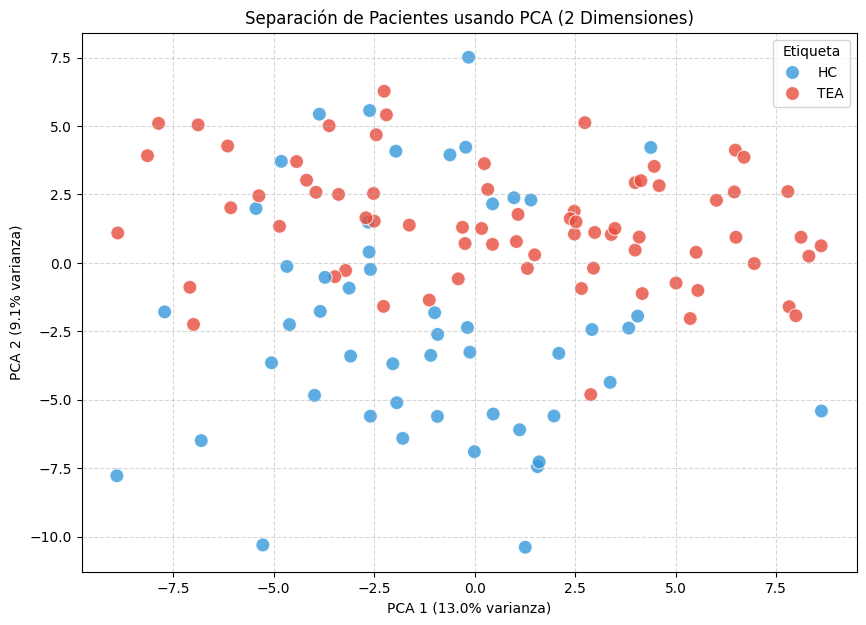

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA


# convierto la data melt en otra


df_wide = dataset.pivot(index='Paciente', columns=['Bacteria_Limpia'], values='AbundanciaTaxonomica')
df_wide = df_wide.fillna(0)
diagnosticos = dataset.groupby('Paciente')['Diagnosticos'].first()

pca_gat = PCA(n_components=5, random_state=42)

# Entrenamos el PCA y transformamos los datos al mismo tiempo
# Esta es la matriz que usarás como 'x' en tus nodos de PyTorch Geometric
caracteristicas_pacientes = pca_gat.fit_transform(df_wide)

print(f"Dimensiones originales: {df_wide.shape}")
print(f"Nuevas dimensiones para la GAT: {caracteristicas_pacientes.shape}")
print(f"Información retenida: {np.sum(pca_gat.explained_variance_ratio_)*100:.2f}%")

pca_visual = PCA(n_components=2, random_state=42)
coordenadas_2d = pca_visual.fit_transform(df_wide)

# Armamos un dataframe temporal para Seaborn
df_grafico = pd.DataFrame(coordenadas_2d, columns=['PCA1', 'PCA2'], index=df_wide.index)
df_grafico['Diagnostico'] = diagnosticos
df_grafico['Etiqueta'] = df_grafico['Diagnostico'].map({1: 'TEA', 0: 'HC'})

# Dibujar el Scatter Plot
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_grafico, 
    x='PCA1', 
    y='PCA2', 
    hue='Etiqueta', 
    palette={'TEA': '#e74c3c', 'HC': '#3498db'}, 
    s=100, 
    alpha=0.8
)
plt.title('Separación de Pacientes usando PCA (2 Dimensiones)')
plt.xlabel(f'PCA 1 ({pca_visual.explained_variance_ratio_[0]*100:.1f}% varianza)')
plt.ylabel(f'PCA 2 ({pca_visual.explained_variance_ratio_[1]*100:.1f}% varianza)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

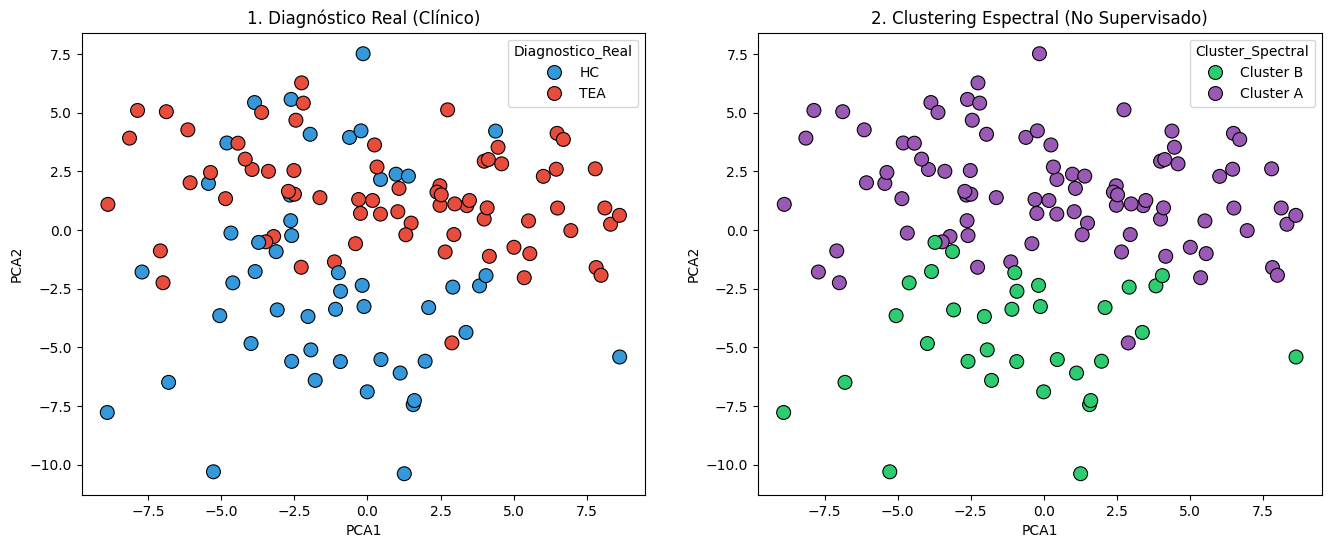

Puntuación de similitud con el diagnóstico real (ARI): 0.5108
[[33 17]
 [ 0 71]]


In [3]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score

spectral = SpectralClustering(
    n_clusters=2, 
    affinity='nearest_neighbors', 
    n_neighbors=5, # Conecta a cada paciente con sus 10 más parecidos
    assign_labels='discretize'
    ,random_state=42
)

# Entrenamos el modelo ciego (solo con los datos matemáticos, sin diagnósticos)
clusters_descubiertos = spectral.fit_predict(caracteristicas_pacientes)

# 4. Preparar datos para graficar en 2D
pca_visual = PCA(n_components=2, random_state=42)
coordenadas_2d = pca_visual.fit_transform(df_wide)

df_plot = pd.DataFrame(coordenadas_2d, columns=['PCA1', 'PCA2'], index=df_wide.index)
# Mapeamos los nombres para la leyenda
df_plot['Diagnostico_Real'] = diagnosticos.map({1: 'TEA', 0: 'HC'})
df_plot['Cluster_Spectral'] = ['Cluster A' if c == 1 else 'Cluster B' for c in clusters_descubiertos]

# 5. Dibujar los gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico Izquierdo (Real)
sns.scatterplot(
    data=df_plot, x='PCA1', y='PCA2', hue='Diagnostico_Real', 
    palette={'TEA': '#e74c3c', 'HC': '#3498db'}, s=100, ax=axes[0], edgecolor='k'
)
axes[0].set_title('1. Diagnóstico Real (Clínico)')

# Gráfico Derecho (Espectral)
sns.scatterplot(
    data=df_plot, x='PCA1', y='PCA2', hue='Cluster_Spectral', 
    palette={'Cluster A': '#9b59b6', 'Cluster B': '#2ecc71'}, s=100, ax=axes[1], edgecolor='k'
)
axes[1].set_title('2. Clustering Espectral (No Supervisado)')

plt.show()

# 6. Métrica de evaluación clínica
# El Adjusted Rand Index (ARI) mide qué tan parecidos son los clusters descubiertos a la realidad clínica.
# 1.0 es perfecto, 0.0 es puro azar.
#clusters_corregidos = [1 if c == 0 else 0 for c in clusters_descubiertos]
ari = adjusted_rand_score(diagnosticos, clusters_descubiertos)
print(f"Puntuación de similitud con el diagnóstico real (ARI): {ari:.4f}")
from sklearn.metrics import confusion_matrix
print(confusion_matrix(diagnosticos, clusters_descubiertos))


In [4]:
# comienzo reduciendo la dimensionalidad usando PCA
# uso PCA tradicional por el metodo de limpieza antes usado, filtrado de prevalencia, imputacion de ceros y crl

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report


